# Logistic regression: probability of passing a test from study time

In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

from scripts.log_regression_viz import plot_data, plot_init, plot_prediction, plot_training

## Data

saved: C:\Users\Admin\Documents\Study\Projects\eng-regression\outputs\log_regression_data.png


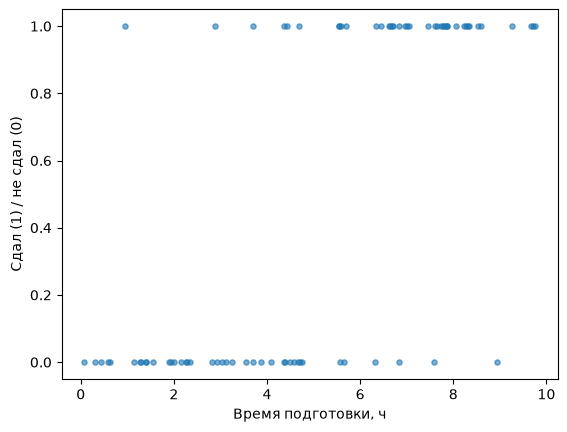

In [2]:
rng = np.random.default_rng(42)
n = 80

hours = rng.uniform(0, 10, n)
p_true = 1 / (1 + np.exp(-0.8 * (hours - 5)))
passed = (rng.random(n) < p_true).astype(float)

df = pd.DataFrame({"hours": hours, "passed": passed})

plot_data(hours, passed)

In [9]:
df.round(1).head()

,hours,passed
0,7.7,1.0
1,4.4,0.0
2,8.6,1.0
3,7.0,1.0
4,0.9,1.0


## Random initialization

In [3]:
X = df["hours"].to_numpy()
Y = df["passed"].to_numpy()

mx, sx = X.mean(), X.std()
Xn = (X - mx) / sx


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def to_original(w_n, b_n):
    w = w_n / sx
    return w, b_n - w * mx


def metrics(w, b):
    p = np.clip(sigmoid(w * X + b), 1e-12, 1 - 1e-12)
    loss = -np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p))
    acc = np.mean((p >= 0.5) == (Y == 1))
    return loss, acc


init_rng = np.random.default_rng(3)
w_n0, b_n0 = init_rng.normal(0, 1, 2)
w_n0 = -abs(w_n0)
w0, b0 = to_original(w_n0, b_n0)
loss0, acc0 = metrics(w0, b0)

plot_init(X, Y, w0, b0, loss0, acc0).show()

saved: C:\Users\Admin\Documents\Study\Projects\eng-regression\outputs\log_regression_init.html
saved: C:\Users\Admin\Documents\Study\Projects\eng-regression\outputs\log_regression_init.png


## Training

In [4]:
lr, epochs = 1.0, 100
w_n, b_n = w_n0, b_n0
hist = {"epoch": [], "w": [], "b": [], "loss": [], "acc": []}


def log(ep, w_n, b_n):
    w, b = to_original(w_n, b_n)
    loss, acc = metrics(w, b)
    for k, v in zip(hist, (ep, w, b, loss, acc), strict=True):
        hist[k].append(v)


log(0, w_n, b_n)
for ep in range(1, epochs + 1):
    err = sigmoid(w_n * Xn + b_n) - Y
    w_n -= lr * np.mean(err * Xn)
    b_n -= lr * np.mean(err)
    log(ep, w_n, b_n)

hist = {k: np.array(v) for k, v in hist.items()}
w_gd, b_gd = hist["w"][-1], hist["b"][-1]

ref = LogisticRegression(C=np.inf, max_iter=10_000).fit(X.reshape(-1, 1), Y)
w_ref, b_ref = ref.coef_[0, 0], ref.intercept_[0]

print(
    f"GD after {epochs} epochs: w={w_gd:.3f}, b={b_gd:.3f}, "
    f"log loss={hist['loss'][-1]:.4f}, accuracy={hist['acc'][-1]:.0%}"
)
print(f"sklearn (no regularization): w={w_ref:.3f}, b={b_ref:.3f}")

GD after 100 epochs: w=0.797, b=-4.105, log loss=0.4045, accuracy=85%
sklearn (no regularization): w=0.798, b=-4.109


## Training animation

In [5]:
plot_training(X, Y, hist, w_ref, b_ref).show()

saved: C:\Users\Admin\Documents\Study\Projects\eng-regression\outputs\log_regression_training.html
saved: C:\Users\Admin\Documents\Study\Projects\eng-regression\outputs\log_regression_training.gif


## Prediction

In [6]:
new_hours = 6
prob = sigmoid(w_gd * new_hours + b_gd)

plot_prediction(X, Y, w_gd, b_gd, new_hours).show()
print(
    f"Study time {new_hours} h -> pass probability {prob:.0%} ({'pass' if prob >= 0.5 else 'fail'})"
)

saved: C:\Users\Admin\Documents\Study\Projects\eng-regression\outputs\log_regression_prediction.html
saved: C:\Users\Admin\Documents\Study\Projects\eng-regression\outputs\log_regression_prediction.png


Study time 6 h -> pass probability 66% (pass)
